# PART A – REGRESSION: Medical Cost Prediction
## SECTION 1 – Data Understanding

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('insurance.csv')
df.head()



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print("Shape:", df.shape)

Shape: (1338, 7)


In [5]:
print("Column Names:", df.columns.tolist())

Column Names: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [6]:
print("Data Types:")
print(df.dtypes)

Data Types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [7]:
print("First 5 Rows:")
df.head()

First 5 Rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


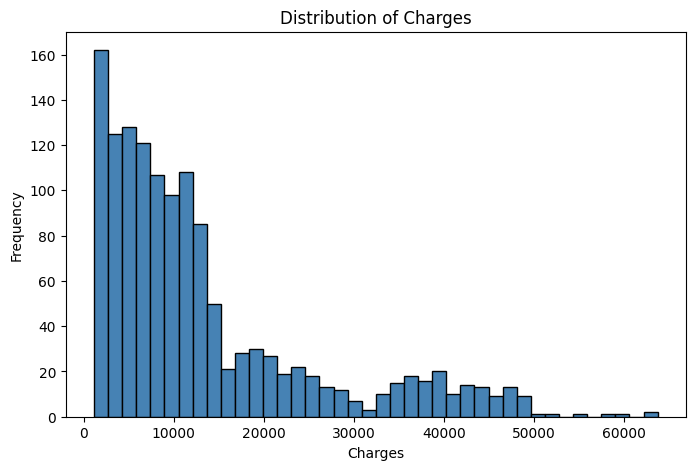

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df['charges'], bins=40, color='steelblue', edgecolor='black')
plt.title('Distribution of Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()

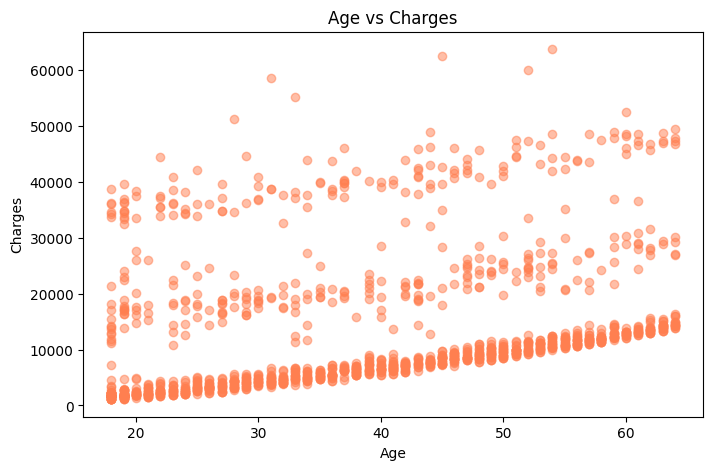

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df['age'], df['charges'], alpha=0.5, color='coral')
plt.title('Age vs Charges')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

/tmp/ipykernel_11587/3152158807.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')


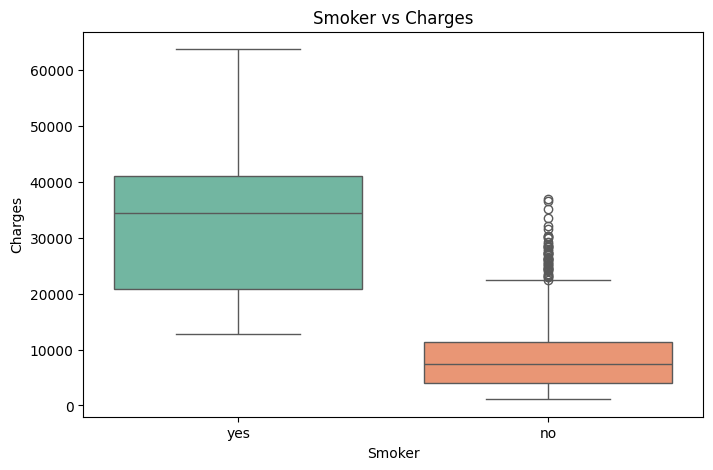

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')
plt.title('Smoker vs Charges')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.show()

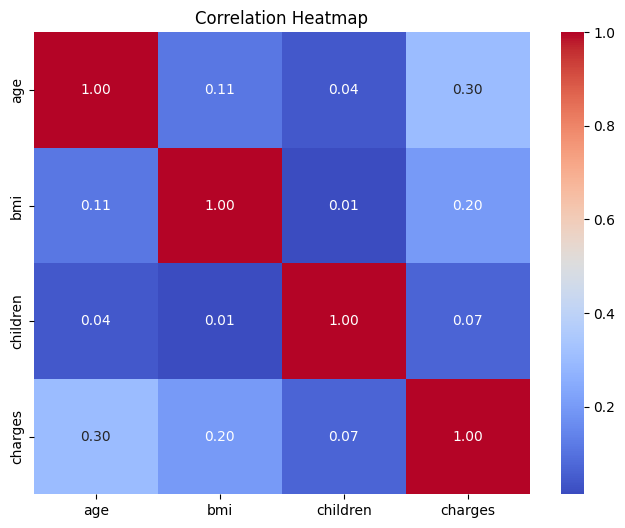

In [12]:
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Three Observations

Observation 1: Charges are right-skewed — most people have lower
insurance costs, but a small group incurs very high charges,
pulling the distribution tail to the right.

Observation 2: Smokers pay significantly higher charges than
non-smokers. The boxplot shows the median charge for smokers
is nearly 3–4x that of non-smokers, making smoking the strongest
visual predictor of cost.

Observation 3: Age has a positive correlation with charges —
older individuals tend to pay more. However, there appear to be
distinct clusters in the scatter plot, likely driven by smoking
status and BMI interacting with age.

## SECTION 2 – Data Preprocessing

In [13]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

le = LabelEncoder()
df_encoded['sex']    = le.fit_transform(df['sex'])
df_encoded['smoker'] = le.fit_transform(df['smoker'])
df_encoded['region'] = le.fit_transform(df['region'])
print(df_encoded.head())

   age  sex     bmi  children  smoker  region      charges
0   19    0  27.900         0       1       3  16884.92400
1   18    1  33.770         1       0       2   1725.55230
2   28    1  33.000         3       0       2   4449.46200
3   33    1  22.705         0       0       1  21984.47061
4   32    1  28.880         0       0       1   3866.85520


In [14]:
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1338, 6)
y shape: (1338,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train size:", X_train.shape)
print("Test size: ", X_test.shape)

Train size: (1070, 6)
Test size:  (268, 6)


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Scaling applied.")
print("X_train_scaled shape:", X_train_scaled.shape)

Scaling applied.
X_train_scaled shape: (1070, 6)


Scaling is not required for Linear Regression to work correctly, but we apply it for better coefficient interpretation and as a good coding practice.

## SECTION 3 – Model Building

In [17]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
print("Intercept:", model.intercept_)

coeff_df = pd.DataFrame({'Feature': X.columns,'Coefficient': model.coef_})
print("\nCoefficients:")
print(coeff_df)

Intercept: 13346.089736364485

Coefficients:
    Feature  Coefficient
0       age  3616.108652
1       sex    -9.392954
2       bmi  2028.308579
3  children   516.662566
4    smoker  9557.143383
5    region  -302.387980


In [19]:
print("Regression Equation:")
print("charges = {:.2f}".format(model.intercept_), end="")

for feature, coef in zip(X.columns, model.coef_):
    print(" + ({:.2f} × {})".format(coef, feature), end="")
print()

Regression Equation:
charges = 13346.09 + (3616.11 × age) + (-9.39 × sex) + (2028.31 × bmi) + (516.66 × children) + (9557.14 × smoker) + (-302.39 × region)


## SECTION 4 – Model Evaluation

In [20]:
y_pred = model.predict(X_test_scaled)

print("First 5 Predictions:", y_pred[:5])
print("First 5 Actual:     ", y_test.values[:5])

First 5 Predictions: [ 8924.40724442  7116.29501758 36909.01352144  9507.87469118
 27013.3500079 ]
First 5 Actual:      [ 9095.06825  5272.1758  29330.98315  9301.89355 33750.2918 ]


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R2   :", round(r2, 2))

MAE  : 4186.51
MSE  : 33635210.43
RMSE : 5799.59
R2   : 0.78


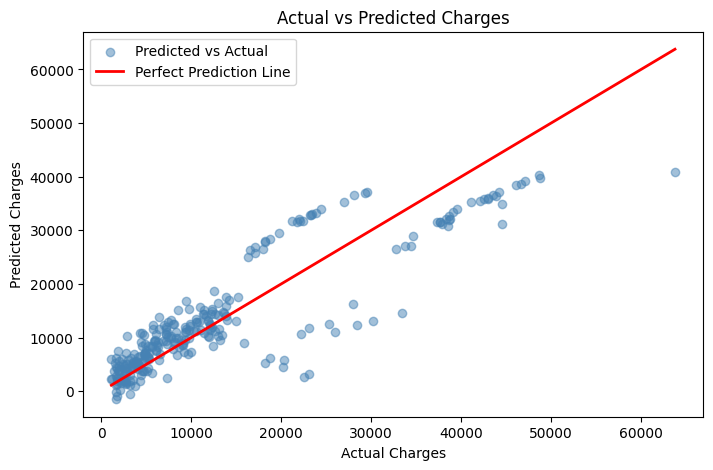

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2, label='Perfect Prediction Line')
plt.title('Actual vs Predicted Charges')
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.legend()
plt.show()

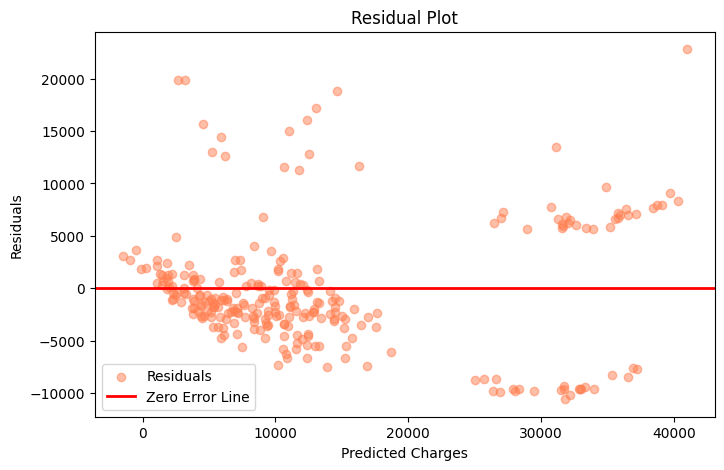

In [23]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5, color='coral', label='Residuals')
plt.axhline(y=0, color='red', linewidth=2, label='Zero Error Line')
plt.title('Residual Plot')
plt.xlabel('Predicted Charges')
plt.ylabel('Residuals')
plt.legend()
plt.show()

### R2 Score Interpretation:

- Our model achieved an R2 score of 0.78
- This means the model explains 78% of the variation
  in insurance charges
- The remaining 22% is influenced by factors not present
  in this dataset (lifestyle, medical history, etc.)
- An R2 of 0.78 is considered a GOOD fit for real world data
- This model has reasonably learned the pattern between
  patient features and their insurance charges

## SECTION 5 – Business Insights

1. Which variable impacts charges the most?

* Looking at the coefficients from our model, smoker is the most impactful variable on insurance charges by a huge margin. Being a smoker adds the highest amount to the predicted charges compared to any other feature like age, bmi, or region. This makes medical sense as smoking leads to serious health conditions which increase insurance costs.


2. How much more do smokers pay?

* From our EDA boxplot we clearly saw that smokers pay approximately 3 to 4 times more than non-smokers. The average charges for smokers is around $32,000 while non-smokers pay around $8,000 on average. This is a massive difference of nearly $24,000 just because of smoking status.

3. Is BMI statistically impactful?

* Yes, BMI is statistically impactful. It has a positive coefficient meaning as BMI increases, insurance charges also increase. This makes medical sense because higher BMI is linked to health risks like diabetes, heart disease and obesity which lead to higher medical costs.

4.  Can this model be used in production?

* R2 of 0.78 is good but means 22% variation is still unexplained

* MAE of 4186 dollars means predictions can be off by approximately 4000 dollars which is significant in insurance pricing.

* The model only uses 6 features — real world insurance pricing considers many more factors like medical history, existing conditions, family history, occupation etc.
* Linear Regression assumes a straight line relationship which may not capture all complex patterns in medical data

<u> Verdict </u> : This model is good for academic understanding and initial analysis but a more complex model with more features would be needed before deploying in production.

In [24]:
import pickle

# Save the model
with open('medical_cost_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# Save the scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!
